<a href="https://colab.research.google.com/github/PriscilaForcel/Cursos_Oficinas_Treinamentos/blob/main/workshop_censo2022_instrutor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Censo Demográfico 2022 para estudos urbanos
## Análise de dados por setores censitários com Python e Google Colab
**Versão do instrutor**: contém roteiro de fala (🗣️) e marcações de tempo (⏱️).

| Parte | Duração | Conteúdo |
|---|---|---|
| **1. Banco de dados e gráficos** | 1h30 | Importação online das bases do IBGE, limpeza, *merge* pelo código do setor, estatística descritiva, gráficos de MG e de Viçosa |
| *Intervalo* | | A base fica salva em `.parquet`, sem precisar baixar de novo |
| **2. Mapas** | 1h30 | Malha de setores, geocódigos, mapas estáticos e interativos, análise espacial simples em Viçosa |

**Fonte:** IBGE, Censo Demográfico 2022, Agregados por Setores Censitários (resultados do universo).

> 🗣️ **Abertura (⏱️ 5 min)**
> - O objetivo é mostrar **o que os dados permitem ver** e **quais ferramentas usar**, não fazer uma pesquisa completa.
> - Cada um sai daqui com um caminho reproduzível: baixar, organizar, descrever, graficar e mapear.
> - O notebook roda inteiro na nuvem (Colab). Nada é instalado no computador e nenhum arquivo do IBGE é salvo manualmente.
> - Combinado: os dados mostram padrões entre **lugares** (setores, municípios). A leitura é responsabilidade do urbanista: não manipular os dados e não afirmar mais do que eles dizem.

---
# PARTE 1: Montando o banco de dados e explorando com gráficos

## 1.1 Preparando o ambiente

> 🗣️ O Colab já vem com `pandas`, `matplotlib`, `seaborn`, `plotly` e `geopandas`. Instalamos só três extras, usados na Parte 2.
> - `pandas`: tabelas · `matplotlib`/`seaborn`: gráficos estáticos · `plotly`: gráficos interativos.

In [ ]:
%pip install -q contextily mapclassify geopy

In [ ]:
import io, re, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from tqdm.auto import tqdm

pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid')

# Geocódigos usados no workshop
UF_MG      = '31'        # Minas Gerais
COD_VICOSA = '3171303'   # Viçosa (MG)

# Endereço das bases no servidor do IBGE
URL_IBGE = 'https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/'
URL_CSV  = URL_IBGE + 'Agregados_por_Setor_csv/'

## 1.2 O que é o setor censitário e como os dados estão organizados

> 🗣️ **(⏱️ 5 min)**
> - **Setor censitário** é a menor unidade territorial de coleta e divulgação do IBGE. Em áreas urbanas costuma ter algumas centenas de domicílios.
> - Os **Agregados por Setores** trazem totais (contagens) para cada setor: pessoas, domicílios, água, esgoto, lixo, idade etc.
> - São 1 arquivo **básico** + 12 **temáticos**. Hoje usaremos:
>   - **Básico**: identificação do setor (município, bairro, situação urbana/rural, área) e totais de pessoas e domicílios;
>   - **Demografia**: pessoas por sexo e faixa etária;
>   - **Características dos domicílios – Parte 2**: água, banheiro, esgoto e lixo, inclusive **por sexo do responsável**.
> - Cada arquivo é uma tabela em que **cada linha é um setor**. O que liga as tabelas é o **código do setor (`CD_SETOR`)**.
> - As variáveis têm códigos (`V00453`...). O significado está no **dicionário de dados**.

## 1.3 Funções auxiliares para ler direto do IBGE

> 🗣️ Não precisa decorar estas funções. Elas fazem o trabalho repetitivo:
> 1. `achar_arquivo`: procura na página do IBGE o nome **atual** do arquivo. O IBGE coloca a data no nome quando atualiza (ex.: `..._BR_20260520.zip`).
> 2. `baixar`: baixa o arquivo **para a memória**, sem salvar no computador.
> 3. `ler_agregado`: abre o `.zip`, lê o CSV em partes (o arquivo é do **Brasil inteiro**), guarda **só as colunas pedidas** e **só os setores de MG**. O filtro usa o código do setor, que começa por `31`.
>
> Detalhes que fazem diferença com dados do IBGE:
> - `dtype=str`: lemos tudo como texto para **não perder zeros à esquerda** dos códigos e para tratar o "X" de sigilo depois.
> - o separador costuma ser `;` e o decimal, `,` (padrão brasileiro).

In [ ]:
def achar_arquivo(url_pasta, padrao):
    '''Procura na listagem do IBGE o arquivo cujo nome combina com o padrão.'''
    html = requests.get(url_pasta, timeout=60).text
    nomes = sorted(set(re.findall(r'href="([^"?/]+)"', html)))
    nomes = [n for n in nomes if re.search(padrao, n, flags=re.I)]
    if not nomes:
        raise FileNotFoundError(f'Nenhum arquivo com o padrão {padrao} em {url_pasta}')
    return url_pasta + nomes[-1]


def baixar(url):
    '''Baixa um arquivo para a memória (não salva em disco), com barra de progresso.'''
    r = requests.get(url, stream=True, timeout=300)
    r.raise_for_status()
    total = int(r.headers.get('content-length', 0))
    buffer = io.BytesIO()
    with tqdm(total=total, unit='B', unit_scale=True, desc=url.split('/')[-1][:45]) as barra:
        for bloco in r.iter_content(chunk_size=1024 * 1024):
            buffer.write(bloco)
            barra.update(len(bloco))
    buffer.seek(0)
    return buffer


def padronizar(nome):
    '''Padroniza nomes de colunas: sem espaços, sem BOM e em maiúsculas.'''
    return nome.strip().lstrip('﻿').upper()


def ler_agregado(url, colunas, prefixo_uf=UF_MG):
    '''Lê um CSV zipado do IBGE, mantendo só as colunas pedidas e os setores da UF.'''
    buffer = baixar(url)
    with zipfile.ZipFile(buffer) as z:
        nome_csv = [n for n in z.namelist() if n.lower().endswith('.csv')][0]

        # descobre o separador olhando a primeira linha
        with z.open(nome_csv) as f:
            cabecalho = f.readline()
        separador = ';' if cabecalho.count(b';') > cabecalho.count(b',') else ','

        # a coluna do código do setor muda de nome entre arquivos (CD_SETOR, CD_setor, setor...):
        # usamos a primeira coluna que contém "SETOR" (ou, se não houver, a primeira coluna)
        nomes = [padronizar(c.strip('"')) for c in cabecalho.decode('latin-1').strip().split(separador)]
        col_setor = next((c for c in nomes if 'SETOR' in c), nomes[0])

        desejadas = {padronizar(c) for c in colunas} | {col_setor}
        for codificacao in ['utf-8-sig', 'latin-1']:   # tenta UTF-8; se falhar, Latin-1
            try:
                partes = []
                with z.open(nome_csv) as f:
                    leitor = pd.read_csv(f, sep=separador, encoding=codificacao, dtype=str,
                                         usecols=lambda c: padronizar(c) in desejadas,
                                         chunksize=100_000)
                    for bloco in leitor:
                        bloco.columns = [padronizar(c) for c in bloco.columns]
                        bloco = bloco.rename(columns={col_setor: 'CD_SETOR'})
                        partes.append(bloco[bloco['CD_SETOR'].str.strip().str.startswith(prefixo_uf)])
                break
            except UnicodeDecodeError:
                continue

    df = pd.concat(partes, ignore_index=True)
    faltando = {padronizar(c) for c in colunas} - set(df.columns)
    print(f'{nome_csv}: {len(df):,} setores e {df.shape[1]} colunas (coluna do setor: {col_setor})'.replace(',', '.'))
    if faltando:
        print('  Atenção, colunas não encontradas:', sorted(faltando))
    return df

## 1.4 O dicionário de dados

> 🗣️ **(⏱️ 5 min)** Antes de baixar os dados, abrimos o dicionário (também direto da internet). A função `buscar` funciona como um "Ctrl+F" no dicionário.
> Mostrar: `buscar('caçamba')` devolve o lixo em caçamba no total, por cor/raça e por **sexo do responsável** (V00453 e V00454).

In [ ]:
url_dic = achar_arquivo(URL_IBGE, r'dicionario.*\.xlsx$')
abas = pd.read_excel(baixar(url_dic), sheet_name=None)
dicionario = pd.concat([a for a in abas.values() if 'Variável' in a.columns], ignore_index=True)
dicionario = dicionario[['Tema', 'Variável', 'Descrição']].dropna(subset=['Variável'])

def buscar(*termos):
    '''Busca variáveis no dicionário que contenham TODOS os termos informados.'''
    filtro = pd.Series(True, index=dicionario.index)
    for t in termos:
        filtro &= dicionario['Descrição'].str.contains(t, case=False, na=False)
    with pd.option_context('display.max_colwidth', 150):
        display(dicionario.loc[filtro, ['Variável', 'Descrição']])

buscar('raça')

dicionario_de_dados_agregados_por_setores_cen:   0%|          | 0.00/124k [00:00<?, ?B/s]

,Variável,Descrição
98,V00090,"Domicílios Particulares Permanentes Ocupados, Tipo de espécie é casa, Cor ou raça da pessoa responsável pelo domicílio é branca"
99,V00091,"Domicílios Particulares Permanentes Ocupados, Tipo de espécie é casa, Cor ou raça da pessoa responsável pelo domicílio é preta"
100,V00092,"Domicílios Particulares Permanentes Ocupados, Tipo de espécie é casa, Cor ou raça da pessoa responsável pelo domicílio é amarela"
101,V00093,"Domicílios Particulares Permanentes Ocupados, Tipo de espécie é casa, Cor ou raça da pessoa responsável pelo domicílio é parda"
102,V00094,"Domicílios Particulares Permanentes Ocupados, Tipo de espécie é casa, Cor ou raça da pessoa responsável pelo domicílio é indígena"
...,...,...
3541,V07142,"Sexo feminino, 10 anos ou mais, Cor ou raça é branca - em domicílios coletivos"
3542,V07143,"Sexo feminino, 10 anos ou mais, Cor ou raça é preta - em domicílios coletivos"
3543,V07144,"Sexo feminino, 10 anos ou mais, Cor ou raça é amarela - em domicílios coletivos"
3544,V07145,"Sexo feminino, 10 anos ou mais, Cor ou raça é parda - em domicílios coletivos"


In [ ]:
buscar('lixo', 'sexo')

,Variável,Descrição
459,V00451,"Domicílios Particulares Permanentes Ocupados, Lixo coletado no domicílio por serviço de limpeza, Sexo da pessoa responsável pelo domicílio é mascu..."
460,V00452,"Domicílios Particulares Permanentes Ocupados, Lixo coletado no domicílio por serviço de limpeza, Sexo da pessoa responsável pelo domicílio é feminino"
461,V00453,"Domicílios Particulares Permanentes Ocupados, Lixo depositado em caçamba de serviço de limpeza, Sexo da pessoa responsável pelo domicílio é masculino"
462,V00454,"Domicílios Particulares Permanentes Ocupados, Lixo depositado em caçamba de serviço de limpeza, Sexo da pessoa responsável pelo domicílio é feminino"
463,V00455,"Domicílios Particulares Permanentes Ocupados, Lixo queimado na propriedade, Sexo da pessoa responsável pelo domicílio é masculino"
464,V00456,"Domicílios Particulares Permanentes Ocupados, Lixo queimado na propriedade, Sexo da pessoa responsável pelo domicílio é feminino"
465,V00457,"Domicílios Particulares Permanentes Ocupados, Lixo enterrado na propriedade, Sexo da pessoa responsável pelo domicílio é masculino"
466,V00458,"Domicílios Particulares Permanentes Ocupados, Lixo enterrado na propriedade, Sexo da pessoa responsável pelo domicílio é feminino"
467,V00459,"Domicílios Particulares Permanentes Ocupados, Lixo jogado em terreno baldio, encosta ou área pública, Sexo da pessoa responsável pelo domicílio é ..."
468,V00460,"Domicílios Particulares Permanentes Ocupados, Lixo jogado em terreno baldio, encosta ou área pública, Sexo da pessoa responsável pelo domicílio é ..."


## 1.5 Escolhendo as variáveis

> 🗣️ **(⏱️ 5 min)** Ler só o necessário economiza memória e tempo (o arquivo de domicílios tem 406 variáveis).
> Atenção às siglas: **DPPO** = Domicílio Particular Permanente Ocupado. A pessoa **responsável** é quem os moradores indicam como responsável pelo domicílio.
>
> Destaque: o Censo 2022 cruza saneamento com **sexo (e cor/raça) da pessoa responsável**. Isso permite comparar, por exemplo, *domicílios chefiados por homens* × *chefiados por mulheres* que usam caçamba.

In [ ]:
# --- Básico: identificação do setor e totais
COLS_BASICO = ['CD_SETOR', 'SITUACAO', 'AREA_KM2', 'CD_MUN', 'NM_MUN', 'CD_DIST', 'NM_DIST',
               'CD_BAIRRO', 'NM_BAIRRO', 'NM_RGINT',
               'V0001',   # total de pessoas
               'V0002',   # total de domicílios
               'V0005',   # média de moradores por domicílio particular ocupado
               'V0007']   # domicílios particulares ocupados

# --- Demografia: moradores, sexo e faixas etárias
COLS_DEMOG = [f'V0{n}' for n in range(1006, 1042)]   # V01006 a V01041

# --- Domicílios parte 2: lixo, água, banheiro e esgoto
LIXO_SEXO = {   # destino do lixo: (responsável homem, responsável mulher)
    'Coletado no domicílio':  ('V00451', 'V00452'),
    'Depositado em caçamba':  ('V00453', 'V00454'),
    'Queimado':               ('V00455', 'V00456'),
    'Enterrado':              ('V00457', 'V00458'),
    'Terreno baldio/encosta': ('V00459', 'V00460'),
    'Outro destino':          ('V00461', 'V00462'),
}
AGUA_ENCANADA_SEXO = {   # (homem, mulher)
    'Encanada até dentro de casa': ('V00226', 'V00227'),
    'Encanada só no terreno':      ('V00228', 'V00229'),
    'Não chega encanada':          ('V00230', 'V00231'),
}
AGUA_FORMA = {'V00111': 'Rede geral', 'V00112': 'Poço profundo/artesiano', 'V00113': 'Poço raso/cacimba',
              'V00114': 'Fonte/nascente', 'V00115': 'Carro-pipa', 'V00116': 'Água da chuva',
              'V00117': 'Rios/açudes/córregos', 'V00118': 'Outra forma'}
BANHEIROS = {'V00232': '1 banheiro', 'V00233': '2 banheiros', 'V00234': '3 banheiros',
             'V00235': '4 ou mais', 'V00236': 'Só banheiro de uso comum',
             'V00237': 'Só sanitário ou buraco', 'V00238': 'Sem banheiro nem sanitário'}
ESGOTO = {'V00309': 'Rede geral ou pluvial', 'V00310': 'Fossa séptica ligada à rede',
          'V00311': 'Fossa séptica não ligada', 'V00312': 'Fossa rudimentar ou buraco',
          'V00313': 'Vala', 'V00314': 'Rio, lago, córrego ou mar', 'V00315': 'Outra forma',
          'V00316': 'Sem banheiro nem sanitário'}

COLS_DOM2 = ([v for par in LIXO_SEXO.values() for v in par]
             + [v for par in AGUA_ENCANADA_SEXO.values() for v in par]
             + list(AGUA_FORMA) + list(BANHEIROS) + list(ESGOTO))
print(len(COLS_DOM2), 'variáveis de domicílio selecionadas')

41 variáveis de domicílio selecionadas


## 1.6 Importação direta do IBGE

> 🗣️ **(⏱️ 10 min, enquanto baixa)** Esta célula leva alguns minutos: são arquivos nacionais de 15 a 80 MB compactados. Aproveitar o tempo para:
> - abrir o site do IBGE e mostrar a pasta dos agregados;
> - comentar que **cada base vira uma tabela (DataFrame)** com uma linha por setor.
>
> ⚠️ Se o servidor do IBGE estiver fora do ar ou muito lento, use o **Plano B** (próxima célula).

In [ ]:
url_basico = achar_arquivo(URL_CSV, r'basico_BR.*\.zip$')
url_demog  = achar_arquivo(URL_CSV, r'demografia_BR.*\.zip$')
url_dom2   = achar_arquivo(URL_CSV, r'caracteristicas_domicilio2_BR.*\.zip$')

basico     = ler_agregado(url_basico, COLS_BASICO)
demografia = ler_agregado(url_demog,  COLS_DEMOG)
domicilio2 = ler_agregado(url_dom2,   COLS_DOM2)

Agregados_por_setores_basico_BR_20260520.zip:   0%|          | 0.00/15.4M [00:00<?, ?B/s]

Agregados_por_setores_basico_BR.csv: 51.387 setores e 14 colunas (coluna do setor: CD_SETOR)


Agregados_por_setores_demografia_BR.zip:   0%|          | 0.00/22.6M [00:00<?, ?B/s]

Agregados_por_setores_demografia_BR.csv: 50.929 setores e 37 colunas (coluna do setor: CD_SETOR)


Agregados_por_setores_caracteristicas_domicil:   0%|          | 0.00/84.0M [00:00<?, ?B/s]

Agregados_por_setores_caracteristicas_domicilio2_BR_20250417.csv: 50.929 setores e 42 colunas (coluna do setor: SETOR)


### Plano B: base consolidada no Zenodo (só se o IBGE falhar)
> 🗣️ Mesma informação, já reunida num único arquivo **Parquet** (formato colunar, rápido). Lemos só as colunas de que precisamos e filtramos MG. Depois, **pule o merge** (seção 1.8): a base já vem unida. Explicar o merge conceitualmente mesmo assim.

In [ ]:
USAR_PLANO_B = False   # mude para True só se o download do IBGE falhar

if USAR_PLANO_B:
    import fsspec, pyarrow.parquet as pq
    URL_ZENODO = 'https://zenodo.org/records/23821338/files/UNIVERSO_2022_NACIONAL_V2.parquet?download=1'
    try:   # lê só as colunas necessárias, sem baixar o arquivo inteiro
        arquivo = pq.ParquetFile(fsspec.open(URL_ZENODO).open())
    except Exception:   # se o servidor não permitir, baixa o arquivo inteiro para a memória
        arquivo = pq.ParquetFile(baixar(URL_ZENODO))
    desejadas = {padronizar(c) for c in COLS_BASICO + COLS_DEMOG + COLS_DOM2}
    colunas = [c for c in arquivo.schema_arrow.names if padronizar(c) in desejadas]
    plano_b = arquivo.read(columns=colunas).to_pandas()
    plano_b.columns = [padronizar(c) for c in plano_b.columns]
    plano_b['CD_SETOR'] = plano_b['CD_SETOR'].astype(str)
    plano_b = plano_b[plano_b['CD_SETOR'].str.startswith(UF_MG)].astype(str)
    print('Setores de MG:', len(plano_b), '| colunas ausentes:', sorted(desejadas - set(plano_b.columns)))

## 1.7 Primeira olhada e limpeza

> 🗣️ **(⏱️ 10 min)**
> - `head()` mostra as primeiras linhas; `shape`, o tamanho (linhas × colunas).
> - **Sigilo estatístico**: em setores com **menos de 5 domicílios**, o IBGE oculta a maioria dos valores com **"X"**, para proteger os informantes. Isso não é erro: é proteção de dados.
> - Na limpeza: (1) o código do setor fica só com dígitos; (2) "X" vira **vazio (NaN)**; (3) vírgula decimal vira ponto e o texto vira número.

In [ ]:
basico.head()

,CD_SETOR,SITUACAO,AREA_KM2,CD_MUN,NM_MUN,CD_DIST,NM_DIST,CD_BAIRRO,NM_BAIRRO,NM_RGINT,V0001,V0002,V0005,V0007
0,310010405000001,Urbana,"0,2709339",3100104,Abadia dos Dourados,310010405,Abadia dos Dourados,.,NaN,Uberlândia,458,195,"2,6",174
1,310010405000002,Urbana,"0,1762519",3100104,Abadia dos Dourados,310010405,Abadia dos Dourados,.,NaN,Uberlândia,220,127,"2,2",99
2,310010405000003,Urbana,"0,1388593",3100104,Abadia dos Dourados,310010405,Abadia dos Dourados,.,NaN,Uberlândia,373,198,"2,4",157
3,310010405000004,Urbana,"0,2247410",3100104,Abadia dos Dourados,310010405,Abadia dos Dourados,.,NaN,Uberlândia,440,249,"2,3",192
4,310010405000005,Urbana,"0,1111726",3100104,Abadia dos Dourados,310010405,Abadia dos Dourados,.,NaN,Uberlândia,398,208,"2,3",173


In [ ]:
print('Setores com algum "X" (sigilo) no arquivo de domicílios:',
      (domicilio2 == 'X').any(axis=1).sum())

Setores com algum "X" (sigilo) no arquivo de domicílios: 44155


In [ ]:
def limpar(df):
    '''Padroniza o código do setor e converte as variáveis V... (e a área) para número.'''
    df = df.copy()
    df['CD_SETOR'] = df['CD_SETOR'].str.replace(r'\D', '', regex=True)
    numericas = [c for c in df.columns if re.fullmatch(r'V\d+', c) or c == 'AREA_KM2']
    for c in numericas:
        df[c] = pd.to_numeric(df[c].str.strip().str.replace(',', '.', regex=False), errors='coerce')
    return df

basico, demografia, domicilio2 = limpar(basico), limpar(demografia), limpar(domicilio2)
basico.dtypes.head(15)

,0
CD_SETOR,object
SITUACAO,object
AREA_KM2,float64
CD_MUN,object
NM_MUN,object
CD_DIST,object
NM_DIST,object
CD_BAIRRO,object
NM_BAIRRO,object
NM_RGINT,object


## 1.8 Juntando as tabelas: `merge` pelo código do setor

> 🗣️ **(⏱️ 10 min)** Este é o coração da Parte 1.
> - `merge` junta duas tabelas pela coluna em comum, a **chave** (`CD_SETOR`). É o mesmo que o PROCV do Excel ou a junção de tabelas do QGIS.
> - `how='left'`: mantém **todos** os setores do básico, mesmo os que não aparecem na outra tabela.
> - `validate='one_to_one'`: garante que cada setor aparece uma única vez dos dois lados (protege contra duplicação).
> - `indicator=True`: cria a coluna `_merge` dizendo se cada linha achou par (`both`) ou não (`left_only`).
> - **Sempre conferir** o resultado: quantas linhas casaram?

In [ ]:
if USAR_PLANO_B:
    base = limpar(plano_b)
else:
    base = basico.merge(demografia, on='CD_SETOR', how='left', validate='one_to_one', indicator=True)
    print('Básico + Demografia:'); print(base['_merge'].value_counts(), '\n')
    base = base.drop(columns='_merge')

    base = base.merge(domicilio2, on='CD_SETOR', how='left', validate='one_to_one', indicator=True)
    print('(Básico + Demografia) + Domicílios 2:'); print(base['_merge'].value_counts())
    base = base.drop(columns='_merge')

base['CD_MUN'] = base['CD_SETOR'].str[:7]   # o município está embutido no código do setor
print('\nBase final:', base.shape)

Básico + Demografia:
_merge
both          50929
left_only       458
right_only        0
Name: count, dtype: int64 

(Básico + Demografia) + Domicílios 2:
_merge
both          50929
left_only       458
right_only        0
Name: count, dtype: int64

Base final: (51387, 91)


In [ ]:
print(f"Municípios de MG: {base['CD_MUN'].nunique()}")
print(f"Setores de MG:    {len(base):,}".replace(',', '.'))
print(f"População de MG:  {base['V0001'].sum():,.0f}".replace(',', '.'))
base.groupby('SITUACAO')['V0001'].agg(['count', 'sum']).rename(columns={'count': 'setores', 'sum': 'pessoas'})

Municípios de MG: 853
Setores de MG:    51.387
População de MG:  20.539.989


,setores,pessoas
SITUACAO,,
Rural,11525,2418095
Urbana,39798,18121894


## 1.9 De contagens a percentuais

> 🗣️ **(⏱️ 10 min)**
> - Os agregados trazem **contagens absolutas**. Setores e municípios têm tamanhos muito diferentes, então comparar contagens engana (Belo Horizonte sempre terá "mais" de tudo).
> - Por isso **normalizamos em %**: número de domicílios com a característica ÷ total de domicílios do grupo.
> - Ex.: `% caçamba (resp. mulher)` = domicílios chefiados por mulheres com lixo em caçamba ÷ **total de domicílios chefiados por mulheres**.
> - **Ordem importa**: para o município, primeiro **somamos as contagens** dos setores e **depois** calculamos o %. Nunca tirar média de percentuais de setores.

In [ ]:
def pct(numerador, denominador):
    '''Percentual seguro: vazio quando o denominador é zero ou ausente.'''
    return (100 * numerador / denominador.replace(0, np.nan)).round(2)

def calcular_indicadores(df):
    '''Recebe CONTAGENS (de setores ou já somadas por município) e devolve percentuais.'''
    ind = pd.DataFrame(index=df.index)
    homens   = df[[h for h, m in LIXO_SEXO.values()]].sum(axis=1, min_count=1)  # domicílios com resp. homem
    mulheres = df[[m for h, m in LIXO_SEXO.values()]].sum(axis=1, min_count=1)  # domicílios com resp. mulher
    ind['pct_cacamba_resp_homem']  = pct(df['V00453'], homens)
    ind['pct_cacamba_resp_mulher'] = pct(df['V00454'], mulheres)
    ind['pct_resp_mulher']         = pct(mulheres, homens + mulheres)
    ind['pct_sem_rede_agua']       = 100 - pct(df['V00111'], df[list(AGUA_FORMA)].sum(axis=1, min_count=1))
    ind['pct_sem_banheiro_exclusivo'] = pct(df[['V00236', 'V00237', 'V00238']].sum(axis=1),
                                            df[list(BANHEIROS)].sum(axis=1, min_count=1))
    return ind

# Agregação dos setores por município (somando contagens)
contagens = [c for c in base.columns if re.fullmatch(r'V\d+', c) and c not in ('V0005',)]
municipios = base.groupby(['CD_MUN', 'NM_MUN', 'NM_RGINT'], dropna=False)[contagens].sum(min_count=1).reset_index()
municipios = municipios.join(calcular_indicadores(municipios))

vicosa = base[base['CD_MUN'] == COD_VICOSA].copy()
vicosa = vicosa.join(calcular_indicadores(vicosa))
print(f'Viçosa: {len(vicosa)} setores e {vicosa["V0001"].sum():,.0f} pessoas'.replace(',', '.'))

Viçosa: 178 setores e 76.430 pessoas


## 1.10 Estatística descritiva

> 🗣️ **(⏱️ 5 min)** `describe()` resume cada coluna: quantidade de valores válidos (`count`), média, desvio padrão, mínimo, quartis e máximo.
> - Em **MG**, cada linha é um **município**; em **Viçosa**, cada linha é um **setor**.
> - O `count` menor que o total de setores em Viçosa mostra os setores em sigilo.
> - Perguntar à turma: a média e a mediana (50%) são parecidas? O que isso indica sobre desigualdade entre lugares?

In [ ]:
indicadores = ['pct_cacamba_resp_homem', 'pct_cacamba_resp_mulher', 'pct_resp_mulher',
               'pct_sem_rede_agua', 'pct_sem_banheiro_exclusivo']
print('MINAS GERAIS: municípios')
display(municipios[indicadores].describe().round(1))
print('VIÇOSA: setores censitários')
display(vicosa[indicadores].describe().round(1))

MINAS GERAIS: municípios


,pct_cacamba_resp_homem,pct_cacamba_resp_mulher,pct_resp_mulher,pct_sem_rede_agua,pct_sem_banheiro_exclusivo
count,853.0,853.0,853.0,853.0,853.0
mean,9.7,7.2,42.5,24.9,0.5
std,11.7,12.1,6.7,15.0,1.6
min,0.0,0.0,19.1,0.5,0.0
25%,1.8,0.8,38.2,13.7,0.0
50%,6.0,3.0,42.8,22.4,0.0
75%,13.0,8.1,46.7,34.3,0.2
max,85.8,92.6,64.1,77.3,28.4


VIÇOSA: setores censitários


,pct_cacamba_resp_homem,pct_cacamba_resp_mulher,pct_resp_mulher,pct_sem_rede_agua,pct_sem_banheiro_exclusivo
count,139.0,134.0,177.0,174.0,177.0
mean,13.6,13.7,47.5,12.0,0.0
std,19.8,19.9,10.4,27.5,0.1
min,0.0,0.0,18.4,0.0,0.0
25%,0.0,0.0,41.6,0.0,0.0
50%,5.0,6.2,49.0,0.0,0.0
75%,17.5,17.2,55.9,5.5,0.0
max,91.3,100.0,66.7,100.0,1.6


## 1.11 Gráficos: panorama de Minas Gerais

> 🗣️ **(⏱️ 20 min para MG e Viçosa)** Três bibliotecas, três "jeitos" de fazer gráfico:
> - **matplotlib**: a base de tudo, controle total;
> - **seaborn**: estatístico e bonito com poucas linhas;
> - **plotly**: **interativo** (passar o mouse, zoom, esconder séries), ótimo para explorar.

### Gráfico 1 (matplotlib): destino do lixo por sexo da pessoa responsável, MG × Viçosa
> 🗣️ O exemplo central: **caçamba, responsável homem (V00453) × responsável mulher (V00454)**, junto com os outros destinos. A comparação é entre **grupos de domicílios** (chefiados por homens × por mulheres), sempre em % de cada grupo.

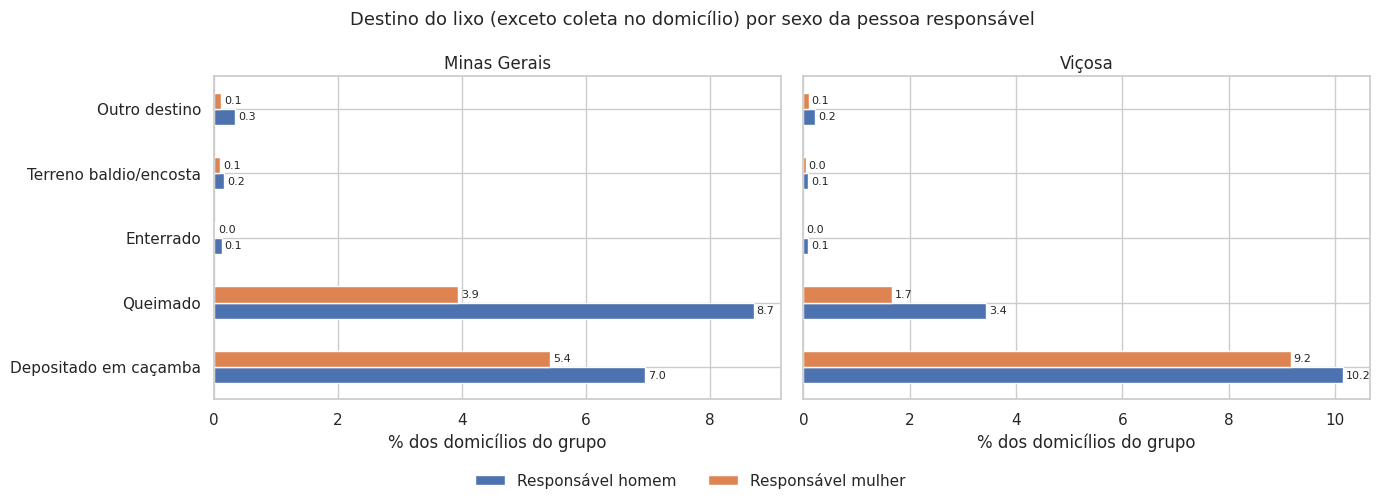

Coleta no domicílio (%):


,Responsável homem,Responsável mulher
Coletado no domicílio,83.71,90.41


In [ ]:
def tabela_lixo_sexo(df):
    '''Distribuição % do destino do lixo para domicílios com responsável homem e mulher.'''
    tab = pd.DataFrame({destino: [df[h].sum(), df[m].sum()] for destino, (h, m) in LIXO_SEXO.items()},
                       index=['Responsável homem', 'Responsável mulher']).T
    return (100 * tab / tab.sum()).round(2)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (nome, df) in zip(eixos, [('Minas Gerais', base), ('Viçosa', vicosa)]):
    tab = tabela_lixo_sexo(df).drop(index='Coletado no domicílio')   # tirar a maior categoria deixa as demais visíveis
    tab.plot.barh(ax=ax, color=['#4C72B0', '#DD8452'], legend=False)
    ax.set_title(nome); ax.set_xlabel('% dos domicílios do grupo'); ax.set_ylabel('')
    for barras in ax.containers:
        ax.bar_label(barras, fmt='%.1f', fontsize=8, padding=2)
fig.legend(['Responsável homem', 'Responsável mulher'], loc='lower center', ncol=2, frameon=False)
fig.suptitle('Destino do lixo (exceto coleta no domicílio) por sexo da pessoa responsável', fontsize=13)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

print('Coleta no domicílio (%):'); tabela_lixo_sexo(base).loc[['Coletado no domicílio']]

### Gráfico 2 (seaborn): como a caçamba varia entre os municípios de MG
> 🗣️ Cada município é uma observação. O histograma mostra **quantos municípios** têm cada faixa de % de caçamba, separando domicílios chefiados por homens e por mulheres. As curvas se sobrepõem ou se deslocam?

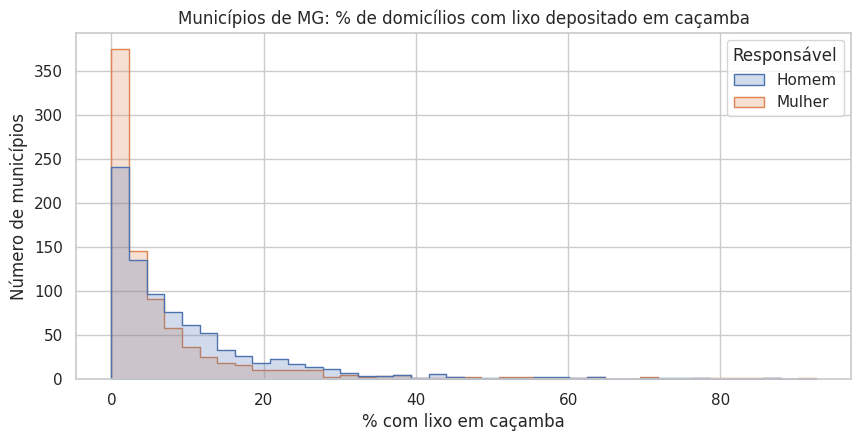

In [ ]:
longo = municipios.melt(value_vars=['pct_cacamba_resp_homem', 'pct_cacamba_resp_mulher'],
                        var_name='Responsável', value_name='% com lixo em caçamba')
longo['Responsável'] = longo['Responsável'].map({'pct_cacamba_resp_homem': 'Homem',
                                                 'pct_cacamba_resp_mulher': 'Mulher'})
plt.figure(figsize=(10, 4.5))
sns.histplot(data=longo, x='% com lixo em caçamba', hue='Responsável', bins=40,
             element='step', palette=['#4C72B0', '#DD8452'])
plt.title('Municípios de MG: % de domicílios com lixo depositado em caçamba')
plt.ylabel('Número de municípios'); plt.show()

### Gráfico 3 (plotly): domicílios sem abastecimento pela rede geral, por região de MG
> 🗣️ Agregamos de novo, agora por **Região Geográfica Intermediária**: o mesmo dado em outra escala. Passe o mouse sobre as barras.

In [ ]:
regioes = base.groupby('NM_RGINT')[list(AGUA_FORMA)].sum()
regioes = (100 * regioes.drop(columns='V00111').sum(axis=1) / regioes.sum(axis=1)).round(1)
regioes = regioes.sort_values().reset_index(name='% sem rede geral')

fig = px.bar(regioes, x='% sem rede geral', y='NM_RGINT', orientation='h',
             labels={'NM_RGINT': ''}, text='% sem rede geral',
             title='Domicílios que não usam a rede geral como principal forma de abastecimento de água')
fig.update_layout(height=500); fig.show()

### Gráfico 4 (plotly): pirâmides etárias, MG × Viçosa
> 🗣️ A pirâmide mostra a estrutura da população. Em **Viçosa** deve aparecer uma "barriga" nas faixas de **15 a 29 anos**: efeito da **universidade**. É um exemplo de como o dado conta a história da cidade.

In [ ]:
FAIXAS = ['0-4', '5-9', '10-14', '15-19', '20-24', '25-29', '30-39', '40-49', '50-59', '60-69', '70+']
HOMENS   = [f'V0{n}' for n in range(1009, 1020)]   # V01009 a V01019
MULHERES = [f'V0{n}' for n in range(1020, 1031)]   # V01020 a V01030

def piramide(df):
    total = df['V01006'].sum()
    return pd.DataFrame({'Faixa etária': FAIXAS,
                         'Homens':   -100 * df[HOMENS].sum().values / total,   # negativo = lado esquerdo
                         'Mulheres':  100 * df[MULHERES].sum().values / total})

dados = pd.concat([piramide(base).assign(Local='Minas Gerais'), piramide(vicosa).assign(Local='Viçosa')])
dados = dados.melt(id_vars=['Faixa etária', 'Local'], var_name='Sexo', value_name='%')
fig = px.bar(dados, x='%', y='Faixa etária', color='Sexo', facet_col='Local', orientation='h',
             barmode='relative', color_discrete_sequence=['#4C72B0', '#DD8452'],
             title='Pirâmide etária (% da população total de cada local)')
fig.update_xaxes(tickvals=[-6, -4, -2, 0, 2, 4, 6], ticktext=['6', '4', '2', '0', '2', '4', '6'])
fig.show()

## 1.12 Gráficos: Viçosa

### Gráfico 5 (pandas + matplotlib): água encanada por sexo da pessoa responsável
> 🗣️ Barras **empilhadas a 100%**: cada barra soma 100% dos domicílios do grupo. Ver o urbano e o rural separadamente ajuda a entender onde estão as diferenças.

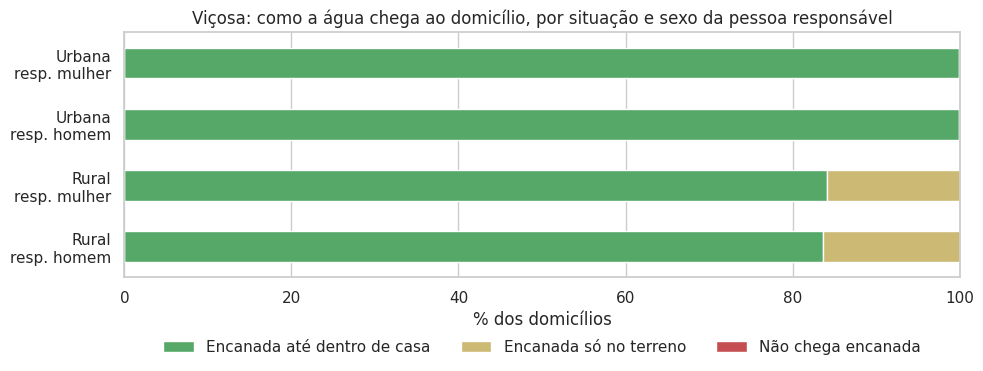

,Encanada até dentro de casa,Encanada só no terreno,Não chega encanada
Rural\nresp. homem,83.7,16.3,0.0
Rural\nresp. mulher,84.1,15.9,0.0
Urbana\nresp. homem,99.9,0.1,0.0
Urbana\nresp. mulher,99.9,0.1,0.0


In [ ]:
linhas = {}
for situacao, df in vicosa.groupby('SITUACAO'):
    for i, sexo in enumerate(['homem', 'mulher']):
        linhas[f'{situacao}\nresp. {sexo}'] = {k: df[v[i]].sum() for k, v in AGUA_ENCANADA_SEXO.items()}
tab = pd.DataFrame(linhas).T
tab = 100 * tab.div(tab.sum(axis=1), axis=0)

ax = tab.plot.barh(stacked=True, figsize=(10, 4), color=['#55A868', '#CCB974', '#C44E52'])
ax.set_xlabel('% dos domicílios'); ax.set_xlim(0, 100)
ax.set_title('Viçosa: como a água chega ao domicílio, por situação e sexo da pessoa responsável')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.tight_layout(); plt.show()
tab.round(1)

### Gráfico 6 (plotly): número de banheiros, Viçosa × MG
> 🗣️ O banheiro é um indicador clássico de **condição habitacional**. Comparar a distribuição da cidade com a do estado situa Viçosa.

In [ ]:
banh = pd.DataFrame({'Viçosa': vicosa[list(BANHEIROS)].sum(), 'Minas Gerais': base[list(BANHEIROS)].sum()})
banh = (100 * banh / banh.sum()).rename(index=BANHEIROS).reset_index(names='Banheiros')
banh = banh.melt(id_vars='Banheiros', var_name='Local', value_name='% dos domicílios')

fig = px.bar(banh, x='Banheiros', y='% dos domicílios', color='Local', barmode='group',
             text_auto='.1f', title='Domicílios por número de banheiros de uso exclusivo',
             color_discrete_sequence=['#8172B3', '#937860'])
fig.show()

## 1.13 Salvando a base para a Parte 2

> 🗣️ **(⏱️ 2 min)** Salvamos a base de MG em **Parquet**: arquivo compacto, rápido e que **preserva os tipos** (o código do setor continua texto). Na Parte 2 não precisamos baixar de novo.
> Se o Colab desconectar no intervalo, o arquivo some junto com a sessão. Por isso há a opção de salvar no Google Drive.

In [ ]:
base.to_parquet('base_mg_setores.parquet', index=False)
print('Base salva: base_mg_setores.parquet')

# Opcional: salvar também no seu Google Drive (sobrevive a desconexões)
# from google.colab import drive
# drive.mount('/content/drive')
# base.to_parquet('/content/drive/MyDrive/base_mg_setores.parquet', index=False)

Base salva: base_mg_setores.parquet


> 🗣️ **Fechamento da Parte 1 (⏱️ 3 min)**
> - Fizemos: importação online → limpeza → merge → percentuais → descrição → gráficos em duas escalas.
> - Os gráficos mostram **quanto**. Na Parte 2 os mapas mostram **onde**.

---
# PARTE 2: Mapas e análise espacial em Viçosa

> 🗣️ **Abertura (⏱️ 3 min)** Nos gráficos vimos lixo, água encanada, banheiros e idade. Nos mapas usaremos **outras variáveis**: densidade demográfica, esgotamento sanitário, chefia feminina dos domicílios e idade (idosos e crianças).

## 2.1 Recarregando o ambiente e a base
> 🗣️ Esta célula funciona mesmo se o Colab tiver reiniciado no intervalo: importa as bibliotecas e lê o Parquet salvo.

In [ ]:
import io, requests, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
warnings.filterwarnings('ignore', message='.*non conformant file extension.*')
import matplotlib.pyplot as plt
import folium
from tqdm.auto import tqdm

COD_VICOSA = '3171303'
URL_MALHA = ('https://ftp.ibge.gov.br/Censos/Censo_Demografico_2022/Agregados_por_Setores_Censitarios/'
             'malha_com_atributos/setores/gpkg/UF/MG/MG_setores_CD2022.gpkg')

def baixar(url):
    '''Baixa um arquivo para a memória (não salva em disco).'''
    r = requests.get(url, stream=True, timeout=300)
    r.raise_for_status()
    buffer = io.BytesIO()
    with tqdm(total=int(r.headers.get('content-length', 0)), unit='B', unit_scale=True) as barra:
        for bloco in r.iter_content(chunk_size=1024 * 1024):
            buffer.write(bloco); barra.update(len(bloco))
    buffer.seek(0)
    return buffer

base = pd.read_parquet('base_mg_setores.parquet')
vic = base[base['CD_MUN'] == COD_VICOSA].copy()
print(f'Viçosa: {len(vic)} setores')

Viçosa: 178 setores


## 2.2 Geocódigos: o endereço numérico do IBGE

> 🗣️ **(⏱️ 5 min)** O código do setor (15 dígitos) é **hierárquico**: carrega o estado, o município, o distrito e o subdistrito.
>
> | Dígitos | Nível | Exemplo (Viçosa) |
> |---|---|---|
> | 2 | UF | `31` = MG |
> | 7 | Município | `3171303` = Viçosa |
> | 9 | Distrito | `317130305` |
> | 11 | Subdistrito | `31713030500` |
> | 15 | Setor | `317130305000001` |
>
> Por isso basta **cortar o texto** para agregar ou filtrar territórios, e é por esse código que ligamos a **tabela** ao **mapa**.

In [ ]:
geo = vic[['CD_SETOR']].head(3).copy()
geo['UF'], geo['Município'] = geo['CD_SETOR'].str[:2], geo['CD_SETOR'].str[:7]
geo['Distrito'], geo['Subdistrito'] = geo['CD_SETOR'].str[:9], geo['CD_SETOR'].str[:11]
display(geo)
print('Distritos de Viçosa:'); vic.groupby('NM_DIST')['V0001'].agg(setores='count', pessoas='sum')

,CD_SETOR,UF,Município,Distrito,Subdistrito
50958,317130305000007,31,3171303,317130305,31713030500
50959,317130305000008,31,3171303,317130305,31713030500
50960,317130305000011,31,3171303,317130305,31713030500


Distritos de Viçosa:


,setores,pessoas
NM_DIST,,
Cachoeira de Santa Cruz,6,1742
Silvestre,18,9004
São José do Triunfo,8,3230
Viçosa,146,62454


## 2.3 Malha de setores direto do IBGE

> 🗣️ **(⏱️ 10 min)**
> - A malha de MG (GeoPackage, ~180 MB) é baixada **para a memória** e lida com o **geopandas**. Um GeoDataFrame é uma tabela do pandas com uma coluna `geometry`.
> - **CRS** (sistema de referência): a malha vem em **SIRGAS 2000 geográfico (EPSG:4674)**, em graus. Para medir **áreas e distâncias** em metros, projetamos para **SIRGAS 2000 / UTM 23S (EPSG:31983)**, a zona de Viçosa.

  0%|          | 0.00/186M [00:00<?, ?B/s]

EPSG:4674 | 178 setores


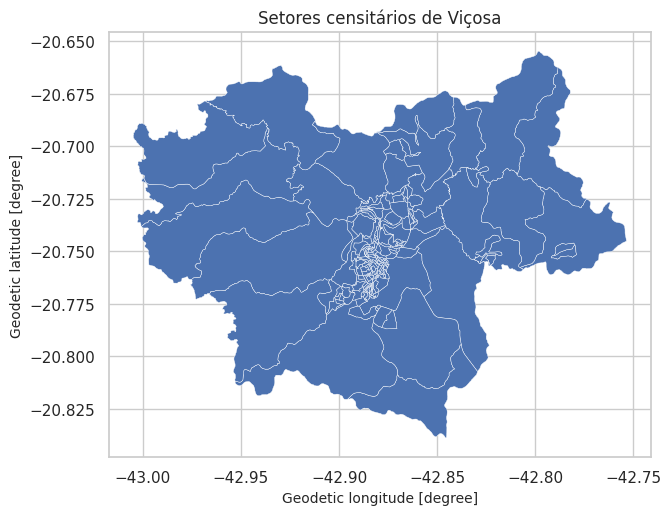

In [ ]:
malha_mg = gpd.read_file(baixar(URL_MALHA))
malha_mg.columns = [c if c == 'geometry' else c.upper() for c in malha_mg.columns]
malha_mg['CD_SETOR'] = malha_mg['CD_SETOR'].astype(str).str.replace(r'\D', '', regex=True)

malha = malha_mg[malha_mg['CD_SETOR'].str.startswith(COD_VICOSA)][['CD_SETOR', 'geometry']].copy()
del malha_mg   # libera memória
print(malha.crs, '|', len(malha), 'setores')
malha.plot(figsize=(7, 7), edgecolor='white', linewidth=0.3); plt.title('Setores censitários de Viçosa'); plt.show()

## 2.4 Juntando tabela e mapa (join por atributo)
> 🗣️ O mesmo `merge` da Parte 1, agora entre a **geometria** e os **dados**. A chave é a mesma: `CD_SETOR`. Conferir se todos os setores casaram.

In [ ]:
mapa = malha.merge(vic, on='CD_SETOR', how='left', validate='one_to_one', indicator=True)
print(mapa['_merge'].value_counts()); mapa = mapa.drop(columns='_merge')

def pct(num, den):
    return (100 * num / den.replace(0, np.nan)).round(2)

ESGOTO = [f'V00{n}' for n in range(309, 317)]   # V00309 a V00316
LIXO_H = ['V00451', 'V00453', 'V00455', 'V00457', 'V00459', 'V00461']
LIXO_M = ['V00452', 'V00454', 'V00456', 'V00458', 'V00460', 'V00462']

mapa = mapa.to_crs(31983)                                   # projeta para metros
mapa['area_km2'] = mapa.geometry.area / 1e6                 # área calculada pela geometria
mapa['densidade'] = (mapa['V0001'] / mapa['area_km2']).round(0)  # habitantes por km²
mapa['pct_esgoto_inadequado'] = pct(mapa[['V00312', 'V00313', 'V00314', 'V00315', 'V00316']].sum(axis=1),
                                    mapa[ESGOTO].sum(axis=1, min_count=1))
mapa['pct_resp_mulher'] = pct(mapa[LIXO_M].sum(axis=1), mapa[LIXO_H + LIXO_M].sum(axis=1, min_count=1))
mapa['pct_idosos']   = pct(mapa[['V01040', 'V01041']].sum(axis=1), mapa['V01006'])           # 60 anos ou mais
mapa['pct_criancas'] = pct(mapa[['V01031', 'V01032', 'V01033']].sum(axis=1), mapa['V01006'])  # 0 a 14 anos

urbano = mapa[mapa['SITUACAO'].astype(str).str.contains('urb', case=False)]
mapa[['densidade', 'pct_esgoto_inadequado', 'pct_resp_mulher', 'pct_idosos', 'pct_criancas']].describe().round(1)

_merge
both          178
left_only       0
right_only      0
Name: count, dtype: int64


,densidade,pct_esgoto_inadequado,pct_resp_mulher,pct_idosos,pct_criancas
count,178.0,177.0,177.0,177.0,177.0
mean,5762.8,11.5,47.5,20.2,14.8
std,4816.2,22.9,10.4,6.8,4.8
min,0.0,0.0,18.4,6.7,0.0
25%,1457.8,0.0,41.6,15.5,12.1
50%,5042.0,0.0,49.0,19.3,15.2
75%,8824.5,12.5,55.9,23.6,17.9
max,20765.0,95.9,66.7,48.1,27.2


> 🗣️ **Esgoto inadequado** aqui = fossa rudimentar/buraco, vala, rio/lago/córrego, outra forma ou ausência de banheiro. É uma escolha de definição, e **escolhas assim precisam ser explicitadas** em qualquer estudo.

## 2.5 Mapa 1 (geopandas): densidade demográfica

> 🗣️ **(⏱️ 8 min)** `gdf.plot(column=...)` faz um mapa coroplético em uma linha.
> - O município inteiro é dominado pelos grandes setores rurais. **Recortar a área urbana** muda completamente a leitura.
> - Cinza = setores sem dado (sigilo).

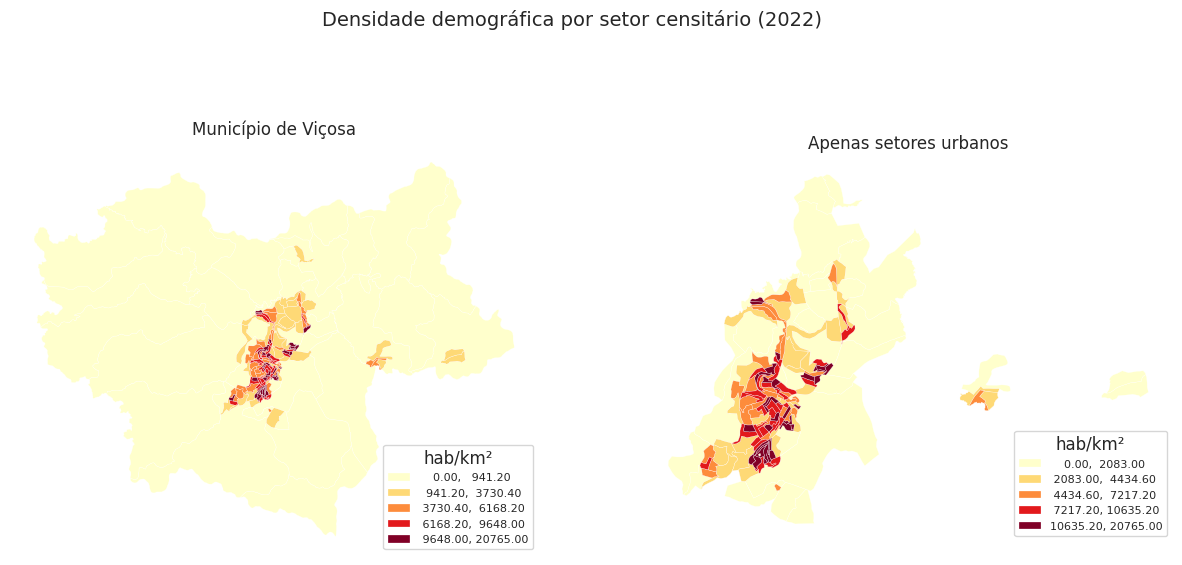

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 7))
opcoes = dict(column='densidade', cmap='YlOrRd', scheme='quantiles', k=5, edgecolor='white', linewidth=0.2,
              legend=True, legend_kwds={'title': 'hab/km²', 'loc': 'lower right', 'fontsize': 8},
              missing_kwds={'color': 'lightgrey', 'label': 'Sem dado'})
mapa.plot(ax=eixos[0], **opcoes);  eixos[0].set_title('Município de Viçosa')
urbano.plot(ax=eixos[1], **opcoes); eixos[1].set_title('Apenas setores urbanos')
for ax in eixos: ax.set_axis_off()
fig.suptitle('Densidade demográfica por setor censitário (2022)', fontsize=14); plt.show()

## 2.6 Mapa 2 (geopandas + contextily): chefia feminina com mapa de fundo
> 🗣️ **(⏱️ 5 min)** O **contextily** adiciona um mapa de fundo (ruas, relevo), o que ajuda o público a se localizar. Mostramos a área urbana com transparência.

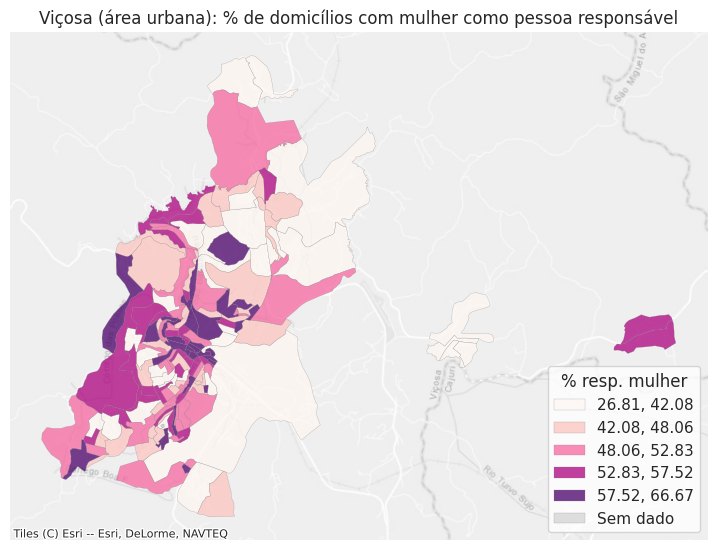

In [ ]:
import contextily as cx

ax = urbano.plot(column='pct_resp_mulher', cmap='RdPu', scheme='quantiles', k=5, alpha=0.75,
                 edgecolor='grey', linewidth=0.2, figsize=(9, 9), legend=True,
                 legend_kwds={'title': '% resp. mulher', 'loc': 'lower right'},
                 missing_kwds={'color': 'lightgrey', 'label': 'Sem dado'})
try:
    cx.add_basemap(ax, crs=urbano.crs, source=cx.providers.Esri.WorldGrayCanvas)
except Exception as erro:
    print('Mapa de fundo indisponível agora:', erro)
ax.set_title('Viçosa (área urbana): % de domicílios com mulher como pessoa responsável'); ax.set_axis_off()
plt.show()

## 2.8 Mapa 4: idosos × crianças lado a lado
> 🗣️ **(⏱️ 5 min)** Mapas lado a lado, **com a mesma escala de cores**, permitem comparar padrões: onde está a população idosa e onde estão as crianças? Pensar em equipamentos públicos: creches, escolas, UBS, praças.

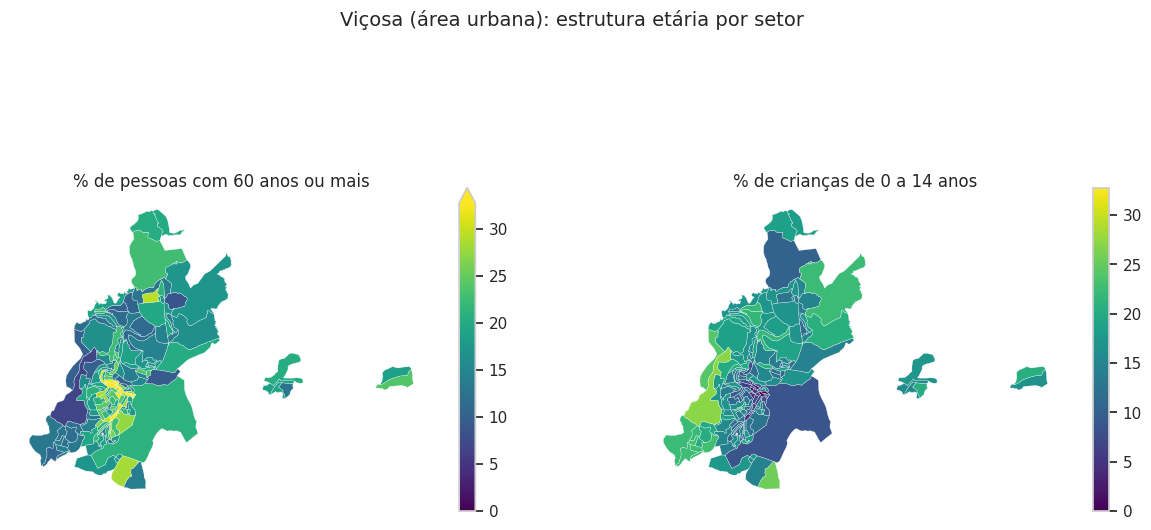

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 7))
limites = dict(vmin=0, vmax=max(urbano['pct_idosos'].quantile(0.95), urbano['pct_criancas'].quantile(0.95)))
for ax, (col, titulo) in zip(eixos, [('pct_idosos', '% de pessoas com 60 anos ou mais'),
                                     ('pct_criancas', '% de crianças de 0 a 14 anos')]):
    urbano.plot(column=col, cmap='viridis', ax=ax, legend=True, edgecolor='white', linewidth=0.2,
                legend_kwds={'shrink': 0.6}, missing_kwds={'color': 'lightgrey'}, **limites)
    ax.set_title(titulo); ax.set_axis_off()
fig.suptitle('Viçosa (área urbana): estrutura etária por setor', fontsize=14); plt.show()

## 2.9 Mapas interativos

### Forma rápida: `explore()`
> 🗣️ **(⏱️ 5 min)** Uma linha transforma o GeoDataFrame em mapa web (usa **folium/Leaflet** por baixo). Zoom, arrastar e passar o mouse para ver os valores.

In [ ]:
colunas_tooltip = ['CD_SETOR', 'NM_BAIRRO', 'V0001', 'densidade', 'pct_esgoto_inadequado']
colunas_tooltip = [c for c in colunas_tooltip if c in urbano.columns]
urbano.explore(column='densidade', scheme='quantiles', k=5, cmap='YlOrRd',
               tooltip=colunas_tooltip, tiles='Esri.WorldGrayCanvas',
               legend_kwds={'caption': 'Densidade (hab/km²)'})

### Mapa com camadas, geocodificação e marcador (folium)
> 🗣️ **(⏱️ 10 min)**
> - Várias variáveis como **camadas** que se ligam e desligam no canto superior direito.
> - **Geocodificação**: transformar um **endereço** em **coordenadas**. Usamos o serviço gratuito Nominatim (OpenStreetMap) para localizar a UFV.
> - O mapa pode ser salvo como **HTML** e aberto em qualquer navegador, ou enviado a um colega.

In [ ]:
from geopy.geocoders import Nominatim

try:
    local = Nominatim(user_agent='workshop_censo2022_vicosa').geocode('Universidade Federal de Viçosa, Viçosa, MG')
    ufv = (local.latitude, local.longitude)
except Exception:
    ufv = (-20.7616, -42.8687)   # coordenada aproximada, caso o serviço não responda
print('UFV:', ufv)

web = urbano.to_crs(4326)   # mapas web usam WGS84 (latitude/longitude)
m = folium.Map(location=ufv, zoom_start=14, tiles='Esri.WorldGrayCanvas')
camadas = [('pct_esgoto_inadequado', 'Esgoto inadequado (%)', 'PuBu', True),
           ('pct_resp_mulher',       'Responsável mulher (%)', 'RdPu', False),
           ('pct_idosos',            '60 anos ou mais (%)',    'viridis', False)]
for coluna, nome, cores, visivel in camadas:
    web.explore(m=m, column=coluna, name=nome, cmap=cores, scheme='quantiles', k=5, show=visivel,
                tooltip=['CD_SETOR', coluna], legend=False, style_kwds={'weight': 0.3, 'fillOpacity': 0.7})
folium.Marker(ufv, tooltip='UFV', icon=folium.Icon(color='green', icon='university', prefix='fa')).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save('mapa_vicosa_censo2022.html')
m

UFV: (-20.7616, -42.8687)


/usr/local/lib/python3.13/dist-packages/mapclassify/classifiers.py:1767: UserWarning:

Not enough unique values in array to form 5 classes. Setting k to 3.



## 2.11 Exportando os resultados
> 🗣️ Mapas estáticos para relatórios (PNG/PDF) e o mapa interativo em HTML. A camada também pode ir para o **QGIS** (GeoPackage).

In [ ]:
ax = urbano.plot(column='densidade', cmap='YlOrRd', scheme='quantiles', k=5, legend=True, figsize=(8, 8),
                 missing_kwds={'color': 'lightgrey'})
ax.set_axis_off(); ax.set_title('Viçosa: densidade demográfica (hab/km²), 2022')
plt.savefig('densidade_vicosa.png', dpi=300, bbox_inches='tight'); plt.close()

colunas_gpkg = ['CD_SETOR', 'SITUACAO', 'V0001', 'densidade', 'pct_esgoto_inadequado',
                'pct_resp_mulher', 'pct_idosos', 'pct_criancas', 'geometry']
mapa[[c for c in colunas_gpkg if c in mapa.columns]].to_file('vicosa_setores_indicadores.gpkg', driver='GPKG')
print('Arquivos gerados: densidade_vicosa.png, mapa_vicosa_censo2022.html, vicosa_setores_indicadores.gpkg')
# from google.colab import files; files.download('mapa_vicosa_censo2022.html')

Arquivos gerados: densidade_vicosa.png, mapa_vicosa_censo2022.html, vicosa_setores_indicadores.gpkg


## Encerramento: potencial analítico e crítico
> 🗣️ **(⏱️ 10 min de conversa)**
> - **O que os dados permitem**: ler desigualdades **intraurbanas** em alta resolução (setor), cruzar saneamento com sexo e cor/raça do responsável e comparar escalas (setor, bairro, município, estado).
> - **Cuidados**:
>   - os dados descrevem **lugares e grupos de domicílios**, não indivíduos;
>   - setores pequenos têm **sigilo** e percentuais instáveis;
>   - a **classificação** e a **escala** mudam a mensagem do mapa;
>   - as **definições** (ex.: "esgoto inadequado") são escolhas que precisam ser declaradas.
> - **Para o planejamento**: diagnóstico de infraestrutura, priorização de investimentos, localização de equipamentos, base para planos diretores e de saneamento, controle social.
> - **Próximos passos**: outros temas (cor ou raça, alfabetização, entorno dos domicílios), outras cidades (basta trocar o geocódigo) e integração com dados municipais.